In [11]:
import torch
import torch.nn.functional as F
import torch.nn.init as init
import matplotlib.pyplot as plt
import random

In [12]:
random.seed(42)
words = open("names.txt", "r").read().splitlines()
random.shuffle(words)
def stoi(c):
    if c == '.': return 26
    return ord(c)-ord('a')
def itos(i):
    if i == 26: return '.'
    return chr(ord('a')+i)

In [13]:
chunk_size = 4
emb_dim = 10
batch_size = 32
n_in = chunk_size*emb_dim
n_outs = [200, 27]

In [14]:
xs = []
ys = []
for word in words:
    context = [26]*chunk_size
    word = word + '.'
    for i in range(len(word)):
        
        xs.append(context)
        ys.append(stoi(word[i]))
        context = context[1:] + [stoi(word[i])]
xs = torch.tensor(xs)
ys = torch.tensor(ys)
xs.shape, ys.shape

(torch.Size([228146, 4]), torch.Size([228146]))

In [15]:
n1 = int(xs.shape[0]*0.8)
n2 = int(xs.shape[0]*0.9)
xdev = xs[n1:n2]
ydev = ys[n1:n2]
xtest = xs[n2:]
ytest = ys[n2:]
xs = xs[:n1]
ys = ys[:n1]

In [16]:
C = torch.randn((27,emb_dim))
W1 = torch.randn(n_in, n_outs[0]) * ((5/3) / n_in**0.5)
W2 = torch.randn(n_outs[0], n_outs[1]) * 0.01
B2 = torch.zeros(n_outs[1])
bngain = torch.ones(1, n_outs[0])
bnbias = torch.zeros(1, n_outs[0])
parameters = [C,W1,W2,B2,bngain,bnbias]
for param in parameters:
    param.requires_grad=True

step: 0, loss 3.283230781555176
step: 1000, loss 2.3314952850341797
step: 2000, loss 2.148709535598755
step: 3000, loss 2.281705856323242
step: 4000, loss 2.3094003200531006
step: 5000, loss 2.2894062995910645
step: 6000, loss 2.5371453762054443
step: 7000, loss 2.3829469680786133
step: 8000, loss 2.498128890991211
step: 9000, loss 2.855937957763672
step: 10000, loss 1.98764169216156
step: 11000, loss 2.2085468769073486
step: 12000, loss 2.176520586013794
step: 13000, loss 2.3546388149261475
step: 14000, loss 2.6566481590270996
step: 15000, loss 2.3530287742614746
step: 16000, loss 2.09455943107605
step: 17000, loss 2.2262775897979736
step: 18000, loss 2.207188129425049
step: 19000, loss 2.4476356506347656
step: 20000, loss 1.9578551054000854
step: 21000, loss 2.10762619972229
step: 22000, loss 2.6320462226867676
step: 23000, loss 1.96089506149292
step: 24000, loss 2.14749813079834
step: 25000, loss 2.4003822803497314
step: 26000, loss 2.256150960922241
step: 27000, loss 2.041841268539

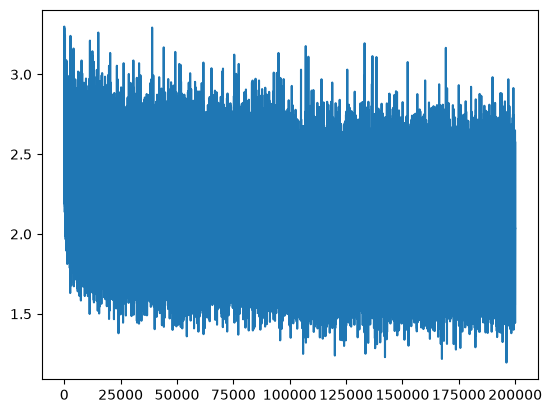

In [17]:
losses = []
for i in range(200000):
    batch = torch.randint(0, xs.shape[0], (batch_size, ))
    x = xs[batch]
    y = ys[batch]
    emb = C[x].view(-1, n_in) 
    hpre = emb @ W1
    # batch x outs[0]
    hpre = bngain*(hpre-hpre.mean(0, keepdim=True))/hpre.std(0, keepdim=True)+bnbias
    h = torch.tanh(hpre)
    logits = h @ W2 + B2
    loss = F.cross_entropy(logits, y)
    for param in parameters: param.grad = None
    loss.backward()
    for param in parameters: param.data -= (0.1 if i < 100000 else 0.01) * param.grad
    losses.append(loss.item())
    if i % 1000 == 0: print(f"step: {i}, loss {loss.item()}")
plt.plot(losses)


In [21]:
emb = C[xs].view(-1, n_in)
hpre = emb @ W1
bnmean = hpre.mean(0,keepdim=True)
bnstd = hpre.std(0,keepdim=True)
bnmean,bnstd

(tensor([[ 0.1625,  0.1034, -2.4947,  0.2502, -0.1363, -0.3506,  0.8264,  0.5289,
           1.0606, -1.2105, -0.7514,  0.5701, -0.7438,  0.3007, -2.9451, -0.5426,
           3.0254,  0.9152,  0.0880, -0.7187, -2.1452,  1.3002,  1.6824, -0.2680,
          -0.6556, -1.6777, -1.4533, -1.2333,  2.6111,  0.2051, -1.0268,  1.6399,
           1.6107,  0.8136,  1.4822, -0.1299, -0.6390, -1.7500, -0.2401,  0.8773,
          -0.4389, -0.4965,  0.3948, -0.2744, -0.7797,  2.2465, -0.9874,  1.4269,
          -0.6617, -0.8335,  0.5291, -1.6786, -0.6381,  2.8228,  1.4829,  1.5234,
           0.6317, -0.5038,  0.7524, -1.8419, -2.1609, -0.9609, -0.1836, -2.4187,
          -0.8795,  0.8986, -0.5803,  2.3483, -1.2783,  0.9603, -1.7149,  0.9268,
           0.7546, -0.4045,  1.2030,  2.6730,  0.4862,  1.1961,  0.4072, -1.4429,
           0.1992,  2.2685,  0.0144, -0.5807, -2.0501,  0.6390,  0.8342, -0.1741,
           2.4441,  0.2978,  0.0481, -1.7739, -1.1160, -0.7117, -0.9238, -1.7161,
           1.701

In [19]:
emb = C[xdev].view(-1, n_in) 
hpre = emb @ W1
hpre = bngain*(hpre-bnmean)/bnstd + bnbias
h = torch.tanh(hpre)
logits = h @ W2 + B2
loss = F.cross_entropy(logits, ydev)
print(loss.data)
emb = C[xtest].view(-1, n_in) 
hpre = emb @ W1
hpre = bngain*(hpre-bnmean)/bnstd + bnbias
h = torch.tanh(hpre)
logits = h @ W2 + B2
loss = F.cross_entropy(logits, ytest)
print(loss.data)


tensor(2.0611)
tensor(2.0578)


In [29]:
for i in range(10):
    name = ""
    context = [26]*chunk_size
    while True:
        emb = C[(context, )].view(-1, emb_dim*chunk_size)
        hpre = emb @ W1
        hpre = bngain*(hpre-bnmean)/bnstd + bnbias
        h = torch.tanh(hpre)
        logits = h @ W2 + B2
        probs = F.softmax(logits, dim = 1)
        idx = torch.multinomial(probs, num_samples=1)
        name+=itos(idx)
        context = context[1:] + [idx]
        if idx == 26: break
    print(name)

wu.
kassidi.
lenni.
japesiz.
bren.
satan.
amrin.
caimus.
dullie.
willua.
